## SENSIBILIDAD DE PONDERACIONES CON PARÁMETROS FIJOS
Compara los agrupamientos de W-KMedoids, W-Hierarchical y W-DBSCAN al modificar los pesos de las características, conservando el dataset y los parámetros de cada algoritmo. Se consideran ocho escenarios y se contrasta cada uno con la ponderación de dominio.

La comprobación inicial reproduce las asignaciones y métricas de referencia. Después se examinan los cambios en asignaciones, tamaños, cobertura y perfiles.

### CONFIGURACIÓN DEL EXPERIMENTO
- Referencia: ponderación de dominio.
- Control: pesos uniformes.
- Variaciones globales: suavizado al 50 % e intensificación al rango `[0.25, 1]`.
- Variaciones por bloque: multiplicación por `0.5` de los pesos del bloque, sin modificar los restantes.
- W-KMedoids: `k=13`, PAM, semilla 42 y distancia euclidiana ponderada precomputada.
- W-Hierarchical: `k=2`, enlace completo y distancia euclidiana ponderada precomputada.
- W-DBSCAN: `eps=0.606`, `min_samples=34`, ponderación antes de PCA y 17 componentes.

Las métricas se calculan en el espacio propio de cada escenario y en el espacio común de las 28 variables procesadas. En W-DBSCAN se evalúan solo las observaciones agrupadas; las diferencias de cobertura deben considerarse al comparar sus métricas.

### INICIALIZACIÓN

In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import os
import platform
import subprocess
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib
from IPython.display import Markdown, display

# Mostrar las figuras en la salida del notebook.
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import sklearn_extra
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_mutual_info_score,
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn_extra.cluster import KMedoids

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)


### CARGA DE DATOS Y PESOS
Se comprueban el hash, las dimensiones y el orden de las variables del dataset de referencia. También se verifica que los pesos coincidan con el esquema registrado en el repositorio, antes de construir los escenarios.

In [2]:
REPO = Path(r"D:\GradoProyec\electocluster")
DATASET = REPO / "data" / "processed" / "lapop_bolivia_2023_processed.csv"
WEIGHTS_PATH = REPO / "src" / "weighting" / "schemas" / "feature_weights.json"
OUTPUT_DIR = REPO / "results" / "pruebas_sensibilidad_ponderacion"
FIGURES_DIR = OUTPUT_DIR / "figuras"
NOTEBOOK_PATH = REPO / "notebooks" / "pruebas_sensibilidad_ponderacion" / "01_sensibilidad_ponderaciones_parametros_fijos.ipynb"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Referencia del dataset y orden de las características procesadas.
EXPECTED_DATASET_SHA256 = "a06b8bb09009b7ac1f1da8817fea11a9b63f0fdde3bab06a1485594faeb8d3dc"
EXPECTED_FEATURES = [
    "edre", "q10inc", "etid", "boletidnew", "boletidnewb", "estratopri", "ur", "ocupoit",
    "q2", "q1tc_r", "q3cn", "q5b", "leng1", "formal", "wf1", "bolcct1a", "bolcct1b",
    "bolcct1c", "estratosec", "q12cn", "q12bn", "gi0n", "smedia3n", "q10e", "q11n",
    "leng4", "wealth_index", "civic_index",
]
# Parámetros que se mantienen constantes en todos los escenarios.
PARAMS = {
    "WKMedoids": {"n_clusters": 13, "method": "pam", "max_iter": 300, "random_state": 42, "metric": "precomputed"},
    "WHierarchical": {"n_clusters": 2, "linkage": "complete", "metric": "precomputed"},
    "WDBSCAN": {"eps": 0.606, "min_samples": 34, "pca_components": 17, "pipeline": "X * weights -> PCA17 -> DBSCAN"},
}
# Variables cuyos pesos se atenúan conjuntamente.
BLOCKS = {
    "atenuacion_socioeconomica": ["edre", "q10inc", "ocupoit", "formal", "wealth_index"],
    "atenuacion_territorial": ["estratopri", "estratosec", "ur"],
    "atenuacion_identidad": ["etid", "boletidnew", "boletidnewb", "leng1", "leng4"],
    "atenuacion_participacion_informacion": ["civic_index", "gi0n", "smedia3n"],
}

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def git(*args: str) -> str:
    return subprocess.run(["git", *args], cwd=REPO, check=True, capture_output=True, text=True).stdout.strip()

dataset_hash = sha256_file(DATASET)
weights_hash = sha256_file(WEIGHTS_PATH)
canonical_weights_document = json.loads(git('show', 'HEAD:src/weighting/schemas/feature_weights.json'))
assert json.loads(WEIGHTS_PATH.read_text(encoding='utf-8')) == canonical_weights_document, "Cambió el esquema canónico de pesos."
branch = git("branch", "--show-current")
commit = git("rev-parse", "HEAD")
git_status_at_execution = git("status", "--short", "--branch")

assert branch == "experiments", f"Rama inesperada: {branch!r}; se requiere 'experiments'."
assert dataset_hash == EXPECTED_DATASET_SHA256, (
    "Cambió el hash del dataset sin una nueva referencia aprobada: "
    f"esperado={EXPECTED_DATASET_SHA256}, observado={dataset_hash}."
)

X = pd.read_csv(DATASET)
assert X.shape == (1706, 28), f"Dimensión inválida: {X.shape}; se esperaba (1706, 28)."
assert X.columns.tolist() == EXPECTED_FEATURES, "Cambió el orden exacto de las 28 características."
assert X.isna().sum().sum() == 0, "El dataset contiene valores faltantes."
assert np.isfinite(X.to_numpy(dtype=float)).all(), "El dataset contiene valores infinitos o no finitos."

weights_document = json.loads(WEIGHTS_PATH.read_text(encoding="utf-8"))
missing_weights = set(EXPECTED_FEATURES) - set(weights_document["features"])
assert not missing_weights, f"Faltan pesos para: {sorted(missing_weights)}"
domain = pd.Series({f: float(weights_document["features"][f]) for f in EXPECTED_FEATURES}, index=EXPECTED_FEATURES)

environment = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__, "scikit_learn_extra": sklearn_extra.__version__,
    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__, "seaborn": sns.__version__,
    "platform": platform.platform(),
}
pd.DataFrame({
    "valor": [str(X.shape), dataset_hash, weights_hash, branch, commit, str(X.isna().sum().sum()), str(np.isfinite(X.to_numpy()).all())]
}, index=["dimensiones", "dataset_sha256", "pesos_sha256", "rama", "commit", "faltantes", "todos_finitos"])


,valor
dimensiones,"(1706, 28)"
dataset_sha256,a06b8bb09009b7ac1f1da8817fea11a9b63f0fdde3bab0...
pesos_sha256,748e45c04aab8e00a2aed2fbc1255da70f1e1a5183015b...
rama,experiments
commit,39215f00a53346094b8989d98e119982fac0239b
faltantes,0
todos_finitos,True


### ESCENARIOS DE PONDERACIÓN
La intensificación transforma los pesos de dominio mediante min–max al intervalo `[0.25, 1]`. Cada atenuación parte del dominio y reduce a la mitad únicamente los pesos del bloque correspondiente. Se comprueba que los ocho escenarios sean distintos y que los pesos uniformes reproduzcan la distancia euclidiana.

In [3]:
def rescale(values: pd.Series, low: float = 0.25, high: float = 1.0) -> pd.Series:
    span = values.max() - values.min()
    assert span > 0
    return low + (values - values.min()) * (high - low) / span

# Escenarios globales: dominio, uniforme, suavizado e intensificado.
scenarios: dict[str, pd.Series] = {
    "dominio": domain.copy(),
    "uniforme": pd.Series(1.0, index=EXPECTED_FEATURES),
    "suavizado_50": 1.0 + 0.5 * (domain - 1.0),
    "intensificado_025_1": rescale(domain),
}
# Añadir las atenuaciones por bloque a partir de los pesos de dominio.
for scenario_name, variables in BLOCKS.items():
    weights = domain.copy()
    weights.loc[variables] *= 0.5
    scenarios[scenario_name] = weights

assert len(scenarios) == 8
for name, weights in scenarios.items():
    assert weights.index.tolist() == EXPECTED_FEATURES
    assert np.isfinite(weights).all() and (weights > 0).all()

for name, variables in BLOCKS.items():
    changed = set(domain.index[~np.isclose(scenarios[name], domain)])
    assert changed == set(variables), f"{name} cambió variables no previstas: {sorted(changed ^ set(variables))}"
    assert np.allclose(scenarios[name].loc[variables], domain.loc[variables] * 0.5)
    external = domain.index.difference(variables)
    assert np.allclose(scenarios[name].loc[external], domain.loc[external])

fingerprints = {}
for name, weights in scenarios.items():
    fingerprint = hashlib.sha256(weights.to_numpy(dtype=float).tobytes()).hexdigest()
    assert fingerprint not in fingerprints, f"Escenario duplicado exactamente: {name} == {fingerprints[fingerprint]}"
    fingerprints[fingerprint] = name

# Control técnico: con pesos unitarios la distancia ponderada coincide con Euclídea.
uniform_weighted = squareform(pdist(X.to_numpy() * np.sqrt(scenarios["uniforme"].to_numpy()), metric="euclidean"))
uniform_euclidean = squareform(pdist(X.to_numpy(), metric="euclidean"))
assert np.allclose(uniform_weighted, uniform_euclidean, atol=1e-12, rtol=0)
del uniform_weighted, uniform_euclidean
gc.collect()

weight_rows = []
for name, weights in scenarios.items():
    for feature, value in weights.items():
        weight_rows.append({
            "escenario": name, "variable": feature, "peso": value,
            "es_dominio": name == "dominio", "bloque_atenuado": next((b for b, vs in BLOCKS.items() if name == b and feature in vs), ""),
        })
weights_df = pd.DataFrame(weight_rows)
weights_df.to_csv(OUTPUT_DIR / "definicion_pesos_escenarios.csv", index=False)
weights_df.pivot(index="variable", columns="escenario", values="peso").round(3)


escenario,atenuacion_identidad,atenuacion_participacion_informacion,atenuacion_socioeconomica,atenuacion_territorial,dominio,intensificado_025_1,suavizado_50,uniforme
variable,,,,,,,,
bolcct1a,0.650,0.650,0.650,0.650,0.65,0.475,0.825,1.0
bolcct1b,0.650,0.650,0.650,0.650,0.65,0.475,0.825,1.0
bolcct1c,0.650,0.650,0.650,0.650,0.65,0.475,0.825,1.0
boletidnew,0.350,0.700,0.700,0.700,0.70,0.550,0.850,1.0
boletidnewb,0.350,0.700,0.700,0.700,0.70,0.550,0.850,1.0
civic_index,0.500,0.250,0.500,0.500,0.50,0.250,0.750,1.0
edre,1.000,1.000,0.500,1.000,1.00,1.000,1.000,1.0
estratopri,0.850,0.850,0.850,0.425,0.85,0.775,0.925,1.0
estratosec,0.600,0.600,0.600,0.300,0.60,0.400,0.800,1.0


### FUNCIONES DE EVALUACIÓN Y CORRESPONDENCIA DE CLUSTERS
La asignación húngara establece la correspondencia que maximiza la superposición con los clusters de dominio. En W-DBSCAN, el ruido (`-1`) se conserva por separado y no interviene en esa correspondencia. Los clusters sin pareja se identifican como `nuevo_*`.

In [4]:
def internal_metrics(coordinates: np.ndarray, labels: np.ndarray, distances: np.ndarray | None = None) -> dict[str, float]:
    labels = np.asarray(labels)
    unique = np.unique(labels)
    assert len(unique) >= 2 and len(labels) > len(unique), "Condiciones inválidas para métricas internas."
    sil = silhouette_score(distances, labels, metric="precomputed") if distances is not None else silhouette_score(coordinates, labels)
    return {
        "silhouette": float(sil),
        "davies_bouldin": float(davies_bouldin_score(coordinates, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(coordinates, labels)),
    }

# Emparejar clusters por superposición, sin confundir sus identificadores.
def align_to_domain(reference: np.ndarray, candidate: np.ndarray, exclude_noise: bool = False):
    ref = np.asarray(reference)
    cand = np.asarray(candidate)
    ref_labels = [int(v) for v in np.unique(ref) if not (exclude_noise and v == -1)]
    cand_labels = [int(v) for v in np.unique(cand) if not (exclude_noise and v == -1)]
    overlap = np.zeros((len(ref_labels), len(cand_labels)), dtype=int)
    for i, r in enumerate(ref_labels):
        for j, c in enumerate(cand_labels):
            overlap[i, j] = int(np.sum((ref == r) & (cand == c)))
    rows, cols = linear_sum_assignment(-overlap)
    mapping: dict[int, int | str] = {cand_labels[j]: ref_labels[i] for i, j in zip(rows, cols)}
    for c in cand_labels:
        mapping.setdefault(c, f"nuevo_{c}")
    if exclude_noise:
        mapping[-1] = -1
    aligned = np.array([mapping[int(v)] for v in cand], dtype=object)
    return aligned, mapping, overlap, ref_labels, cand_labels

def json_mapping(mapping: dict) -> str:
    return json.dumps({str(k): v for k, v in mapping.items()}, ensure_ascii=False, sort_keys=True)

def total_variation_sizes(reference_aligned: np.ndarray, candidate_aligned: np.ndarray) -> float:
    ref = pd.Series(reference_aligned).value_counts(normalize=True)
    cand = pd.Series(candidate_aligned).value_counts(normalize=True)
    keys = ref.index.union(cand.index)
    return float(0.5 * np.abs(ref.reindex(keys, fill_value=0) - cand.reindex(keys, fill_value=0)).sum())


### EJECUCIÓN DE LOS ALGORITMOS
Para cada escenario se calcula una matriz de distancias que comparten W-KMedoids y W-Hierarchical. W-DBSCAN aplica los pesos antes de reajustar PCA con 17 componentes. Los parámetros de agrupamiento permanecen fijos en los ocho escenarios.

In [5]:
labels_store: dict[tuple[str, str], np.ndarray] = {}
metric_rows, execution_rows, coverage_rows = [], [], []
start = time.perf_counter()

for scenario_name, weight_series in scenarios.items():
    print(f"Ejecutando {scenario_name}...")
    w = weight_series.to_numpy(dtype=float)
    weighted_coordinates = X.to_numpy(dtype=float) * np.sqrt(w)
    distance_matrix = squareform(pdist(weighted_coordinates, metric="euclidean"))

    # W-KMedoids sobre la matriz de distancias ponderadas.
    t0 = time.perf_counter()
    wk = KMedoids(
        n_clusters=PARAMS["WKMedoids"]["n_clusters"], metric="precomputed", method="pam",
        max_iter=PARAMS["WKMedoids"]["max_iter"], random_state=PARAMS["WKMedoids"]["random_state"],
    ).fit(distance_matrix)
    wk_labels = wk.labels_.astype(int)
    assert len(wk_labels) == len(X) and len(np.unique(wk_labels)) == 13
    labels_store[("WKMedoids", scenario_name)] = wk_labels.copy()
    for geometry, values in {
        "propia": internal_metrics(weighted_coordinates, wk_labels, distance_matrix),
        "comun": internal_metrics(X.to_numpy(), wk_labels),
    }.items():
        metric_rows.append({"algoritmo": "WKMedoids", "escenario": scenario_name, "geometria": geometry,
                            "poblacion": "todas_1706", "n_evaluado": len(X), **values})
    execution_rows.append({"algoritmo": "WKMedoids", "escenario": scenario_name, "n_clusters": 13,
                           "inercia": float(wk.inertia_), "pca_varianza_explicada": np.nan,
                           "segundos": time.perf_counter() - t0})
    del wk, wk_labels

    # W-Hierarchical utiliza la misma matriz que W-KMedoids.
    t0 = time.perf_counter()
    wh = AgglomerativeClustering(n_clusters=2, linkage="complete", metric="precomputed").fit(distance_matrix)
    wh_labels = wh.labels_.astype(int)
    assert len(wh_labels) == len(X) and len(np.unique(wh_labels)) == 2
    labels_store[("WHierarchical", scenario_name)] = wh_labels.copy()
    for geometry, values in {
        "propia": internal_metrics(weighted_coordinates, wh_labels, distance_matrix),
        "comun": internal_metrics(X.to_numpy(), wh_labels),
    }.items():
        metric_rows.append({"algoritmo": "WHierarchical", "escenario": scenario_name, "geometria": geometry,
                            "poblacion": "todas_1706", "n_evaluado": len(X), **values})
    execution_rows.append({"algoritmo": "WHierarchical", "escenario": scenario_name, "n_clusters": 2,
                           "inercia": np.nan, "pca_varianza_explicada": np.nan,
                           "segundos": time.perf_counter() - t0})
    del wh, wh_labels, distance_matrix, weighted_coordinates
    gc.collect()

    # W-DBSCAN conserva su flujo de ponderación antes de PCA17.
    t0 = time.perf_counter()
    pca = PCA(n_components=17, random_state=RANDOM_STATE)
    pca_coordinates = pca.fit_transform(X.to_numpy(dtype=float) * w)
    db = DBSCAN(eps=0.606, min_samples=34, metric="euclidean", n_jobs=-1).fit(pca_coordinates)
    db_labels = db.labels_.astype(int)
    assert len(db_labels) == len(X)
    labels_store[("WDBSCAN", scenario_name)] = db_labels.copy()
    grouped = db_labels != -1
    n_clusters = len(np.unique(db_labels[grouped])) if grouped.any() else 0
    n_grouped = int(grouped.sum())
    n_noise = int((~grouped).sum())
    coverage_rows.append({
        "algoritmo": "WDBSCAN", "escenario": scenario_name, "n_total": len(X), "n_clusters": n_clusters,
        "n_agrupadas": n_grouped, "cobertura_pct": 100 * n_grouped / len(X),
        "n_ruido": n_noise, "ruido_pct": 100 * n_noise / len(X),
    })
    if n_clusters >= 2 and n_grouped > n_clusters:
        for geometry, coordinates in {"propia": pca_coordinates[grouped], "comun": X.to_numpy()[grouped]}.items():
            values = internal_metrics(coordinates, db_labels[grouped])
            metric_rows.append({"algoritmo": "WDBSCAN", "escenario": scenario_name, "geometria": geometry,
                                "poblacion": "agrupadas_sin_ruido_del_escenario", "n_evaluado": n_grouped, **values})
    else:
        for geometry in ("propia", "comun"):
            metric_rows.append({"algoritmo": "WDBSCAN", "escenario": scenario_name, "geometria": geometry,
                                "poblacion": "no_valida_menos_de_2_clusters", "n_evaluado": n_grouped,
                                "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan})
    execution_rows.append({"algoritmo": "WDBSCAN", "escenario": scenario_name, "n_clusters": n_clusters,
                           "inercia": np.nan, "pca_varianza_explicada": float(pca.explained_variance_ratio_.sum()),
                           "segundos": time.perf_counter() - t0})
    del pca, pca_coordinates, db, db_labels, grouped
    gc.collect()

metrics_df = pd.DataFrame(metric_rows)
executions_df = pd.DataFrame(execution_rows)
coverage_df = pd.DataFrame(coverage_rows)
print(f"Tiempo total: {time.perf_counter() - start:.1f} s")
executions_df


Ejecutando dominio...


Ejecutando uniforme...


Ejecutando suavizado_50...


Ejecutando intensificado_025_1...


Ejecutando atenuacion_socioeconomica...


Ejecutando atenuacion_territorial...


Ejecutando atenuacion_identidad...


Ejecutando atenuacion_participacion_informacion...


Tiempo total: 52.6 s


,algoritmo,escenario,n_clusters,inercia,pca_varianza_explicada,segundos
0,WKMedoids,dominio,13,1906.792269,NaN,7.774856
1,WHierarchical,dominio,2,NaN,NaN,0.140417
2,WDBSCAN,dominio,4,NaN,0.905078,0.247701
3,WKMedoids,uniforme,13,2336.268746,NaN,6.100246
4,WHierarchical,uniforme,2,NaN,NaN,0.127140
5,WDBSCAN,uniforme,0,NaN,0.892944,0.014122
6,WKMedoids,suavizado_50,13,2134.516898,NaN,5.695067
7,WHierarchical,suavizado_50,2,NaN,NaN,0.127238
8,WDBSCAN,suavizado_50,0,NaN,0.892639,0.014084
9,WKMedoids,intensificado_025_1,13,1642.059993,NaN,5.341491


### VERIFICACIÓN DE LA REFERENCIA
Se comparan las asignaciones de dominio con las ejecuciones históricas: ARI igual a 1, misma cantidad de clusters y mismo ruido. Las métricas se comprueban con tolerancia absoluta de `1e-9`, de modo que una permutación de los identificadores de cluster no altere la verificación.

In [6]:
CANONICAL = {
    "WKMedoids": {
        "assignments": REPO / "results" / "assignments" / "wkmedoids_20260903_212424_451905.csv",
        "n_clusters": 13, "n_noise": 0,
        "propia": {"silhouette": 0.10660470136607983, "davies_bouldin": 2.4834680633648007, "calinski_harabasz": 99.85805003962231},
        "comun": {"silhouette": 0.10623499888238168, "davies_bouldin": 2.452128159703432, "calinski_harabasz": 94.95935333260046},
    },
    "WHierarchical": {
        "assignments": REPO / "results" / "assignments" / "whierarchical_clustering_20260903_212427_597150.csv",
        "n_clusters": 2, "n_noise": 0,
        "propia": {"silhouette": 0.15988265892863396, "davies_bouldin": 2.145030183175951, "calinski_harabasz": 294.91586000542753},
        "comun": {"silhouette": 0.14090720223511682, "davies_bouldin": 2.3074104414738756, "calinski_harabasz": 254.6930434573174},
    },
    "WDBSCAN": {
        "assignments": REPO / "results" / "assignments" / "wdbscan_20260903_212428_995836.csv",
        "n_clusters": 4, "n_noise": 1410,
        "propia": {"silhouette": 0.29576400377933976, "davies_bouldin": 1.3593183247417573, "calinski_harabasz": 120.30614949115017},
        "comun": None,
        "pca_varianza_explicada": 0.9050775435926351,
    },
}
baseline_checks = []
for algorithm, expected in CANONICAL.items():
    observed_labels = labels_store[(algorithm, "dominio")]
    historical_labels = pd.read_csv(expected["assignments"])["cluster"].to_numpy(dtype=int)
    ari = adjusted_rand_score(historical_labels, observed_labels)
    observed_clusters = len(np.unique(observed_labels[observed_labels != -1]))
    observed_noise = int((observed_labels == -1).sum())
    assert np.isclose(ari, 1.0, atol=1e-12)
    assert observed_clusters == expected["n_clusters"] and observed_noise == expected["n_noise"]
    for geometry in ("propia", "comun"):
        if expected.get(geometry) is None:
            continue
        row = metrics_df.query("algoritmo == @algorithm and escenario == 'dominio' and geometria == @geometry").iloc[0]
        for metric, target in expected[geometry].items():
            assert np.isclose(row[metric], target, atol=1e-9, rtol=0), (algorithm, geometry, metric, row[metric], target)
    if algorithm == "WDBSCAN":
        explained = executions_df.query("algoritmo == 'WDBSCAN' and escenario == 'dominio'").iloc[0].pca_varianza_explicada
        assert np.isclose(explained, expected["pca_varianza_explicada"], atol=1e-9, rtol=0)
    baseline_checks.append({"algoritmo": algorithm, "ari_vs_canonico": ari,
                            "n_clusters": observed_clusters, "n_ruido": observed_noise, "resultado": "PASS"})
baseline_checks_df = pd.DataFrame(baseline_checks)
baseline_checks_df


,algoritmo,ari_vs_canonico,n_clusters,n_ruido,resultado
0,WKMedoids,1.0,13,0,PASS
1,WHierarchical,1.0,2,0,PASS
2,WDBSCAN,1.0,4,1410,PASS


### COMPARACIÓN DE ASIGNACIONES, TAMAÑOS Y COBERTURA
ARI y AMI consideran todas las etiquetas. La coincidencia exacta y la variación de tamaños se calculan después de establecer la correspondencia con el dominio; esta última incluye el ruido como categoría separada en W-DBSCAN. Permanecer agrupado no implica conservar el mismo cluster.

In [7]:
assignment_rows, mapping_rows, label_rows, size_rows = [], [], [], []

# Comparar cada escenario con el dominio del mismo algoritmo.
for algorithm in ("WKMedoids", "WHierarchical", "WDBSCAN"):
    reference = labels_store[(algorithm, "dominio")]
    for scenario_name in scenarios:
        candidate = labels_store[(algorithm, scenario_name)]
        exclude_noise = algorithm == "WDBSCAN"
        aligned, mapping, overlap, ref_ids, cand_ids = align_to_domain(reference, candidate, exclude_noise=exclude_noise)
        exact = float(np.mean(aligned == reference.astype(object)))
        both_grouped = (reference != -1) & (candidate != -1)
        union_grouped = (reference != -1) | (candidate != -1)
        jaccard = float(both_grouped.sum() / union_grouped.sum()) if union_grouped.any() else np.nan
        assignment_rows.append({
            "algoritmo": algorithm, "escenario": scenario_name,
            "ari_vs_dominio": adjusted_rand_score(reference, candidate),
            "ami_vs_dominio": adjusted_mutual_info_score(reference, candidate),
            "coincidencia_alineada": exact, "coincidencia_alineada_pct": 100 * exact,
            "variacion_total_tamanos": total_variation_sizes(reference.astype(object), aligned),
            "jaccard_conjunto_agrupado": jaccard if exclude_noise else np.nan,
            "agrupadas_en_ambos": int(both_grouped.sum()) if exclude_noise else len(X),
            "mapeo": json_mapping(mapping),
        })
        for candidate_id, reference_id in mapping.items():
            mapping_rows.append({"algoritmo": algorithm, "escenario": scenario_name,
                                 "cluster_escenario": candidate_id, "cluster_dominio_alineado": reference_id,
                                 "es_ruido": candidate_id == -1})
        for observation, (raw, aligned_id) in enumerate(zip(candidate, aligned)):
            label_rows.append({"observacion": observation, "algoritmo": algorithm, "escenario": scenario_name,
                               "etiqueta_original": int(raw), "etiqueta_alineada_dominio": aligned_id,
                               "es_ruido": int(raw) == -1})
        counts = pd.Series(candidate).value_counts().sort_index()
        for raw_id, count in counts.items():
            aligned_id = mapping[int(raw_id)]
            size_rows.append({"algoritmo": algorithm, "escenario": scenario_name, "cluster_original": int(raw_id),
                              "cluster_alineado_dominio": aligned_id, "es_ruido": int(raw_id) == -1,
                              "n": int(count), "porcentaje": 100 * count / len(X)})

assignments_df = pd.DataFrame(assignment_rows)
mappings_df = pd.DataFrame(mapping_rows)
labels_df = pd.DataFrame(label_rows)
sizes_df = pd.DataFrame(size_rows)

domain_grouped = labels_store[("WDBSCAN", "dominio")] != -1
for row in coverage_rows:
    candidate_grouped = labels_store[("WDBSCAN", row["escenario"])] != -1
    row["jaccard_agrupadas_vs_dominio"] = float((domain_grouped & candidate_grouped).sum() / (domain_grouped | candidate_grouped).sum())
    row["agrupadas_en_ambos"] = int((domain_grouped & candidate_grouped).sum())
    row["cambio_n_clusters_vs_dominio"] = int(row["n_clusters"] - CANONICAL["WDBSCAN"]["n_clusters"])
coverage_df = pd.DataFrame(coverage_rows)

summary_sizes = (sizes_df.query("not es_ruido").groupby(["algoritmo", "escenario"], as_index=False)
                 .agg(n_clusters=("cluster_original", "nunique"), tamano_min=("n", "min"), tamano_max=("n", "max")))
summary = (executions_df.merge(assignments_df.drop(columns="mapeo"), on=["algoritmo", "escenario"])
           .merge(summary_sizes, on=["algoritmo", "escenario"], how="left", suffixes=("", "_verificado"))
           .merge(coverage_df, on=["algoritmo", "escenario"], how="left", suffixes=("", "_dbscan")))
summary.sort_values(["algoritmo", "escenario"])


,algoritmo,escenario,n_clusters,inercia,pca_varianza_explicada,segundos,ari_vs_dominio,ami_vs_dominio,coincidencia_alineada,coincidencia_alineada_pct,variacion_total_tamanos,jaccard_conjunto_agrupado,agrupadas_en_ambos,n_clusters_verificado,tamano_min,tamano_max,n_total,n_clusters_dbscan,n_agrupadas,cobertura_pct,n_ruido,ruido_pct,jaccard_agrupadas_vs_dominio,agrupadas_en_ambos_dbscan,cambio_n_clusters_vs_dominio
20,WDBSCAN,atenuacion_identidad,5,NaN,0.926706,0.040245,0.456029,0.466820,0.763775,76.377491,0.179367,0.476974,290,5.0,67.0,223.0,1706.0,5.0,602.0,35.287222,1104.0,64.712778,0.476974,290.0,1.0
23,WDBSCAN,atenuacion_participacion_informacion,4,NaN,0.924619,0.024964,0.892223,0.813344,0.973036,97.303634,0.005862,0.857585,277,4.0,38.0,92.0,1706.0,4.0,304.0,17.819461,1402.0,82.180539,0.857585,277.0,0.0
14,WDBSCAN,atenuacion_socioeconomica,8,NaN,0.926246,0.047301,0.331471,0.413637,0.732122,73.212192,0.257327,0.385753,287,8.0,45.0,154.0,1706.0,8.0,735.0,43.083236,971.0,56.916764,0.385753,287.0,4.0
17,WDBSCAN,atenuacion_territorial,7,NaN,0.893512,0.041152,0.341737,0.413855,0.723329,72.332943,0.253224,0.400821,293,7.0,53.0,204.0,1706.0,7.0,728.0,42.672919,978.0,57.327081,0.400821,293.0,3.0
2,WDBSCAN,dominio,4,NaN,0.905078,0.247701,1.000000,1.000000,1.000000,100.000000,0.000000,1.000000,296,4.0,35.0,90.0,1706.0,4.0,296.0,17.350528,1410.0,82.649472,1.000000,296.0,0.0
11,WDBSCAN,intensificado_025_1,2,NaN,0.943038,0.080897,-0.038584,0.173224,0.398007,39.800703,0.601993,0.256944,296,2.0,252.0,900.0,1706.0,2.0,1152.0,67.526377,554.0,32.473623,0.256944,296.0,-2.0
8,WDBSCAN,suavizado_50,0,NaN,0.892639,0.014084,0.000000,0.000000,0.826495,82.649472,0.173505,0.000000,0,NaN,NaN,NaN,1706.0,0.0,0.0,0.000000,1706.0,100.000000,0.000000,0.0,-4.0
5,WDBSCAN,uniforme,0,NaN,0.892944,0.014122,0.000000,0.000000,0.826495,82.649472,0.173505,0.000000,0,NaN,NaN,NaN,1706.0,0.0,0.0,0.000000,1706.0,100.000000,0.000000,0.0,-4.0
19,WHierarchical,atenuacion_identidad,2,NaN,NaN,0.126991,0.876711,0.790671,0.968933,96.893318,0.020516,NaN,1706,2.0,538.0,1168.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22,WHierarchical,atenuacion_participacion_informacion,2,NaN,NaN,0.130660,0.017864,0.219436,0.603165,60.316530,0.396835,NaN,1706,2.0,526.0,1180.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### COMPARACIÓN DE PERFILES
Se comparan las medias de las 28 características procesadas. La diferencia absoluta media por variable se pondera por el tamaño de los clusters del escenario que tienen correspondencia con el dominio. Los clusters sin pareja mantienen sus medias, pero no entran en ese promedio; `n_ponderacion` indica su denominador efectivo.

El ruido se exporta por separado y se excluye del ranking. El ranking principal promedia los escenarios de variación con correspondencias válidas, excluyendo dominio y uniforme. Describe cambios de perfiles, sin atribuir importancia causal a las variables.

In [8]:
profile_rows = []
for algorithm in ("WKMedoids", "WHierarchical", "WDBSCAN"):
    ref_labels = labels_store[(algorithm, "dominio")]
    reference_profiles = X.assign(_cluster=ref_labels).query("_cluster != -1").groupby("_cluster").mean()
    for scenario_name in scenarios:
        candidate = labels_store[(algorithm, scenario_name)]
        _, mapping, _, _, _ = align_to_domain(ref_labels, candidate, exclude_noise=algorithm == "WDBSCAN")
        for raw_cluster in np.unique(candidate):
            mask = candidate == raw_cluster
            aligned_id = mapping[int(raw_cluster)]
            scenario_means = X.loc[mask].mean()
            is_noise = int(raw_cluster) == -1
            matched = (not is_noise) and isinstance(aligned_id, (int, np.integer)) and aligned_id in reference_profiles.index
            baseline_means = reference_profiles.loc[aligned_id] if matched else pd.Series(np.nan, index=EXPECTED_FEATURES)
            for feature in EXPECTED_FEATURES:
                diff = float(scenario_means[feature] - baseline_means[feature]) if matched else np.nan
                profile_rows.append({
                    "algoritmo": algorithm, "escenario": scenario_name, "cluster_original": int(raw_cluster),
                    "cluster_alineado_dominio": aligned_id, "es_ruido": is_noise, "n_cluster": int(mask.sum()),
                    "variable": feature, "media_escenario": float(scenario_means[feature]),
                    "media_dominio_alineado": float(baseline_means[feature]) if matched else np.nan,
                    "diferencia": diff, "diferencia_absoluta": abs(diff) if matched else np.nan,
                })
profiles_df = pd.DataFrame(profile_rows)

# Promediar diferencias solo donde existe correspondencia de perfiles.
matched_profiles = profiles_df.query("not es_ruido and diferencia_absoluta == diferencia_absoluta").copy()
matched_profiles["aporte_ponderado"] = matched_profiles["diferencia_absoluta"] * matched_profiles["n_cluster"]
sensitivity = (matched_profiles.groupby(["algoritmo", "escenario", "variable"], as_index=False)
               .agg(suma_aporte=("aporte_ponderado", "sum"), n_ponderacion=("n_cluster", "sum")))
sensitivity["diferencia_absoluta_media_ponderada"] = sensitivity["suma_aporte"] / sensitivity["n_ponderacion"]
sensitivity["ranking_en_escenario"] = sensitivity.groupby(["algoritmo", "escenario"])["diferencia_absoluta_media_ponderada"].rank(method="dense", ascending=False).astype(int)
sensitivity["incluido_ranking_principal"] = ~sensitivity["escenario"].isin(["dominio", "uniforme"])
aggregate_sensitivity = (sensitivity.query("incluido_ranking_principal")
                         .groupby(["algoritmo", "variable"], as_index=False)
                         .agg(sensibilidad_media=("diferencia_absoluta_media_ponderada", "mean"),
                              sensibilidad_maxima=("diferencia_absoluta_media_ponderada", "max")))
aggregate_sensitivity["ranking_principal"] = aggregate_sensitivity.groupby("algoritmo")["sensibilidad_media"].rank(method="dense", ascending=False).astype(int)
aggregate_sensitivity.sort_values(["algoritmo", "ranking_principal"]).groupby("algoritmo").head(10)


,algoritmo,variable,sensibilidad_media,sensibilidad_maxima,ranking_principal
3,WDBSCAN,boletidnew,0.169007,0.444860,1
1,WDBSCAN,bolcct1b,0.142152,0.427951,2
0,WDBSCAN,bolcct1a,0.103410,0.350694,3
8,WDBSCAN,estratosec,0.102673,0.353324,4
25,WDBSCAN,ur,0.061738,0.308688,5
4,WDBSCAN,boletidnewb,0.050079,0.116911,6
7,WDBSCAN,estratopri,0.046985,0.077851,7
26,WDBSCAN,wealth_index,0.039246,0.064433,8
10,WDBSCAN,formal,0.039223,0.144898,9
22,WDBSCAN,q3cn,0.036762,0.052613,10


### EXPORTACIÓN DE RESULTADOS
Se guardan las tablas de métricas, asignaciones, tamaños, cobertura y perfiles. Las figuras siguientes resumen las comparaciones y se conservan también como archivos PNG.

El paquete de evidencia conserva las tablas agregadas, las figuras y el manifiesto. Las etiquetas por observación (`etiquetas.csv`) y la síntesis independiente (`sintesis_metodologica.md`) se generan para uso local y se excluyen de la publicación; la síntesis también puede consultarse en la salida de este notebook.

In [9]:
metrics_df.to_csv(OUTPUT_DIR / "comparacion_metricas.csv", index=False)
assignments_df.to_csv(OUTPUT_DIR / "comparacion_asignaciones.csv", index=False)
summary.to_csv(OUTPUT_DIR / "resumen_escenarios.csv", index=False)
labels_df.to_csv(OUTPUT_DIR / "etiquetas.csv", index=False)
sizes_df.to_csv(OUTPUT_DIR / "distribucion_tamanos.csv", index=False)
coverage_df.to_csv(OUTPUT_DIR / "cobertura_ruido.csv", index=False)
mappings_df.to_csv(OUTPUT_DIR / "correspondencia_etiquetas.csv", index=False)
profiles_df.to_csv(OUTPUT_DIR / "comparacion_perfiles.csv", index=False)
sensitivity.to_csv(OUTPUT_DIR / "variables_mas_sensibles_por_escenario.csv", index=False)
aggregate_sensitivity.to_csv(OUTPUT_DIR / "variables_mas_sensibles.csv", index=False)

size_noise = summary[["algoritmo", "escenario", "n_clusters", "tamano_min", "tamano_max", "variacion_total_tamanos"]].copy()
size_noise = size_noise.merge(coverage_df[["algoritmo", "escenario", "n_agrupadas", "cobertura_pct", "n_ruido", "ruido_pct", "jaccard_agrupadas_vs_dominio", "cambio_n_clusters_vs_dominio"]], on=["algoritmo", "escenario"], how="left")
size_noise.to_csv(OUTPUT_DIR / "comparacion_tamanos_ruido.csv", index=False)

scenario_order = list(scenarios)
palette = sns.color_palette("colorblind", 3)

### SIMILITUD DE ASIGNACIONES

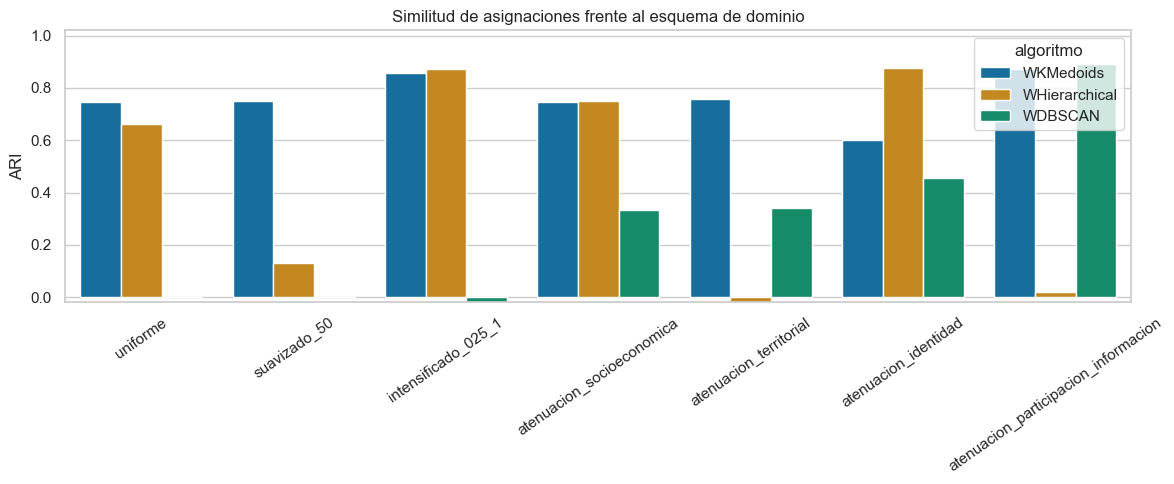

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=assignments_df.query("escenario != 'dominio'"), x="escenario", y="ari_vs_dominio", hue="algoritmo", ax=ax, palette=palette)
ax.set(title="Similitud de asignaciones frente al esquema de dominio", xlabel="", ylabel="ARI", ylim=(-0.02, 1.02))
ax.tick_params(axis="x", rotation=35)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "ari_vs_dominio.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

### DISTRIBUCIÓN DE TAMAÑOS

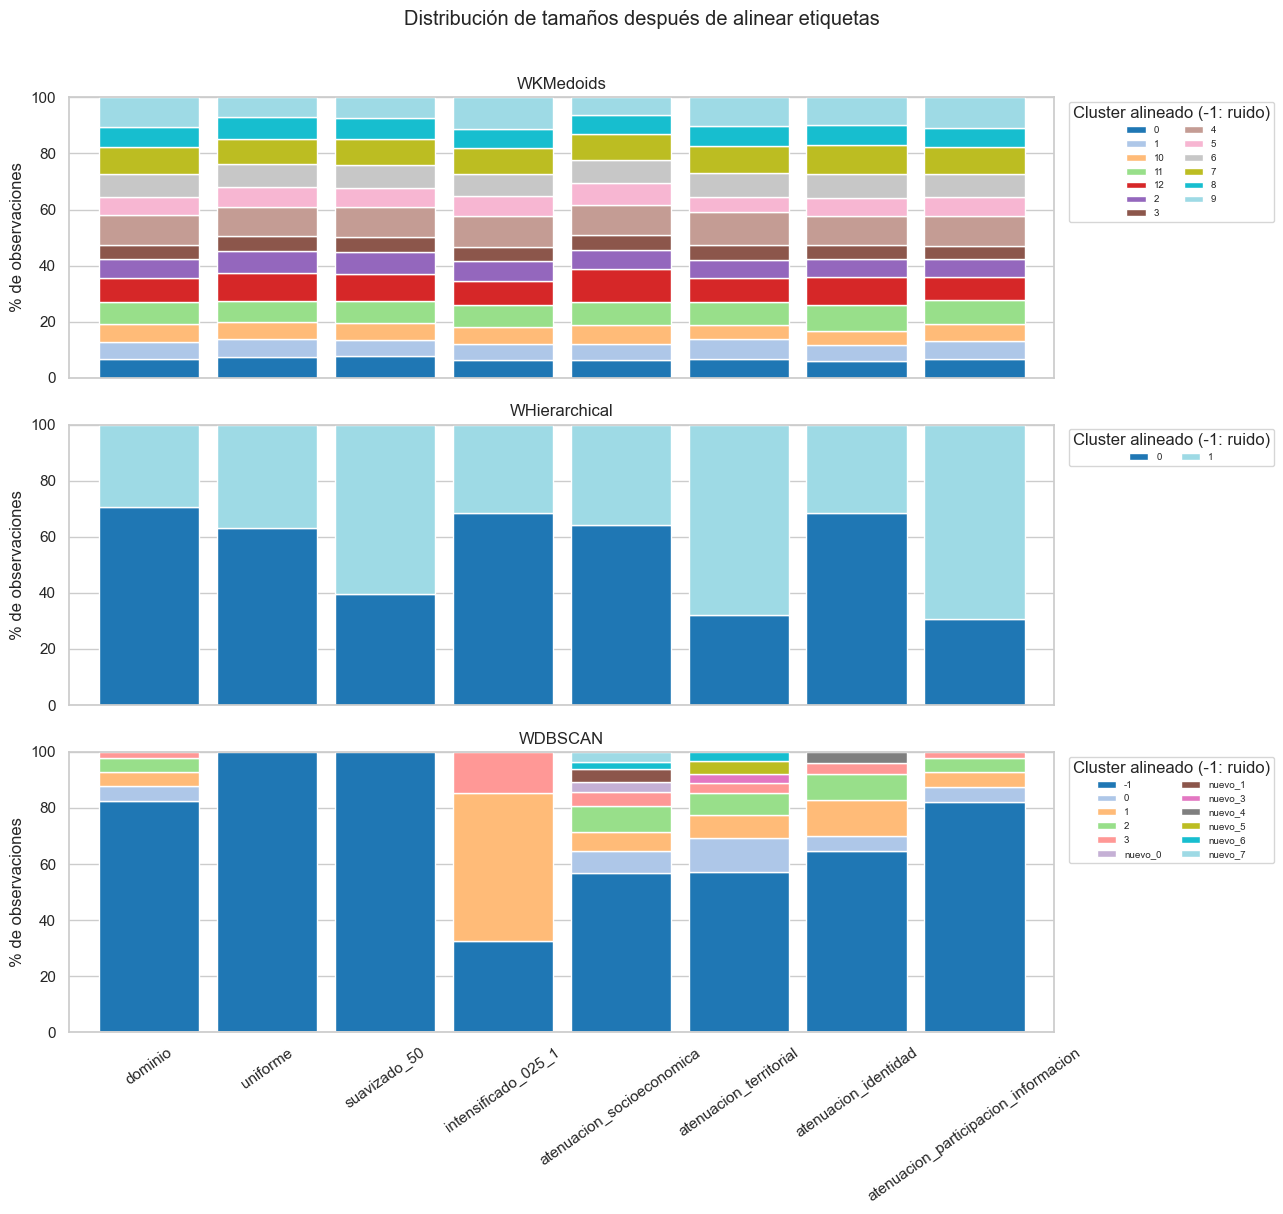

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for ax, algorithm in zip(axes, ("WKMedoids", "WHierarchical", "WDBSCAN")):
    plot_data = sizes_df.query("algoritmo == @algorithm").copy()
    plot_data["cluster"] = plot_data["cluster_alineado_dominio"].astype(str)
    pivot = plot_data.pivot_table(index="escenario", columns="cluster", values="porcentaje", aggfunc="sum", fill_value=0).reindex(scenario_order)
    pivot.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.85, legend=False)
    ax.set(title=algorithm, xlabel="", ylabel="% de observaciones", ylim=(0, 100))
    ax.legend(title='Cluster alineado (-1: ruido)', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=7, ncol=2)
axes[-1].tick_params(axis="x", rotation=35)
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Distribución de tamaños después de alinear etiquetas", y=1.01)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "distribucion_tamanos_alineados.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

### COBERTURA Y RUIDO DE W-DBSCAN

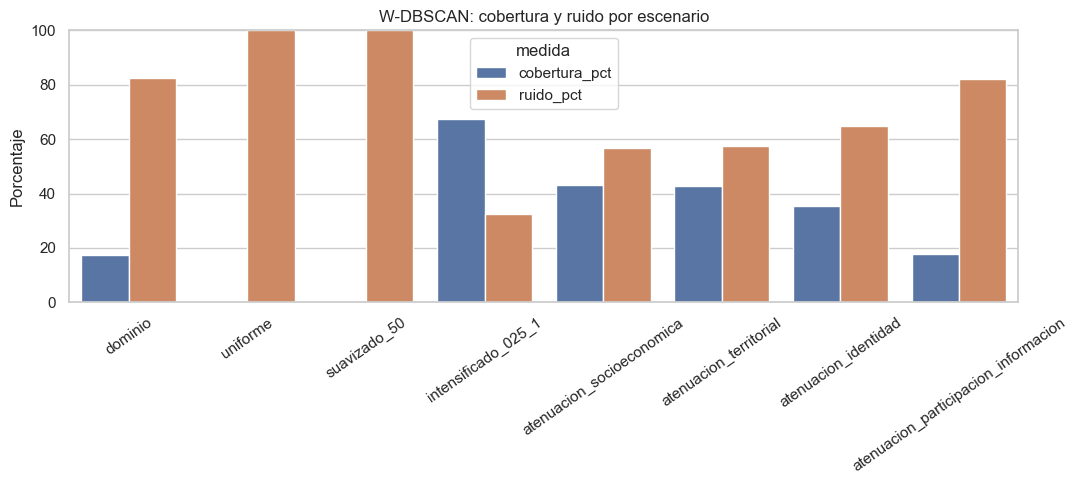

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
noise_plot = coverage_df.melt(id_vars="escenario", value_vars=["cobertura_pct", "ruido_pct"], var_name="medida", value_name="porcentaje")
sns.barplot(data=noise_plot, x="escenario", y="porcentaje", hue="medida", ax=ax)
ax.set(title="W-DBSCAN: cobertura y ruido por escenario", xlabel="", ylabel="Porcentaje", ylim=(0, 100))
ax.tick_params(axis="x", rotation=35)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "wdbscan_cobertura_ruido.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

### MÉTRICAS INTERNAS

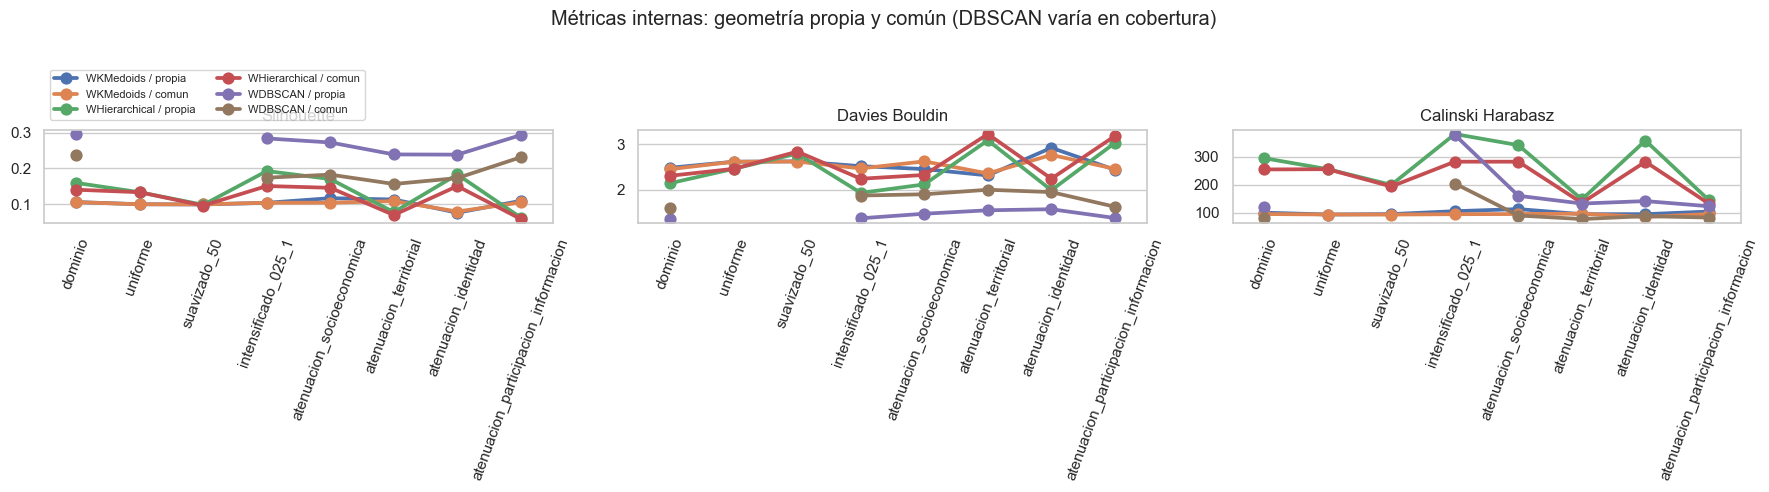

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"]):
    plot_metrics = metrics_df.copy()
    plot_metrics['lectura'] = plot_metrics['algoritmo'] + ' / ' + plot_metrics['geometria']
    sns.pointplot(data=plot_metrics, x="escenario", y=metric, hue="lectura", ax=ax, errorbar=None)
    ax.set(title=metric.replace("_", " ").title(), xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=70)
    if ax is not axes[0] and ax.legend_ is not None: ax.legend_.remove()
fig.suptitle("Métricas internas: geometría propia y común (DBSCAN varía en cobertura)")
axes[0].legend(bbox_to_anchor=(0, 1.05), loc='lower left', fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "metricas_geometrias.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

### CAMBIOS EN LOS PERFILES

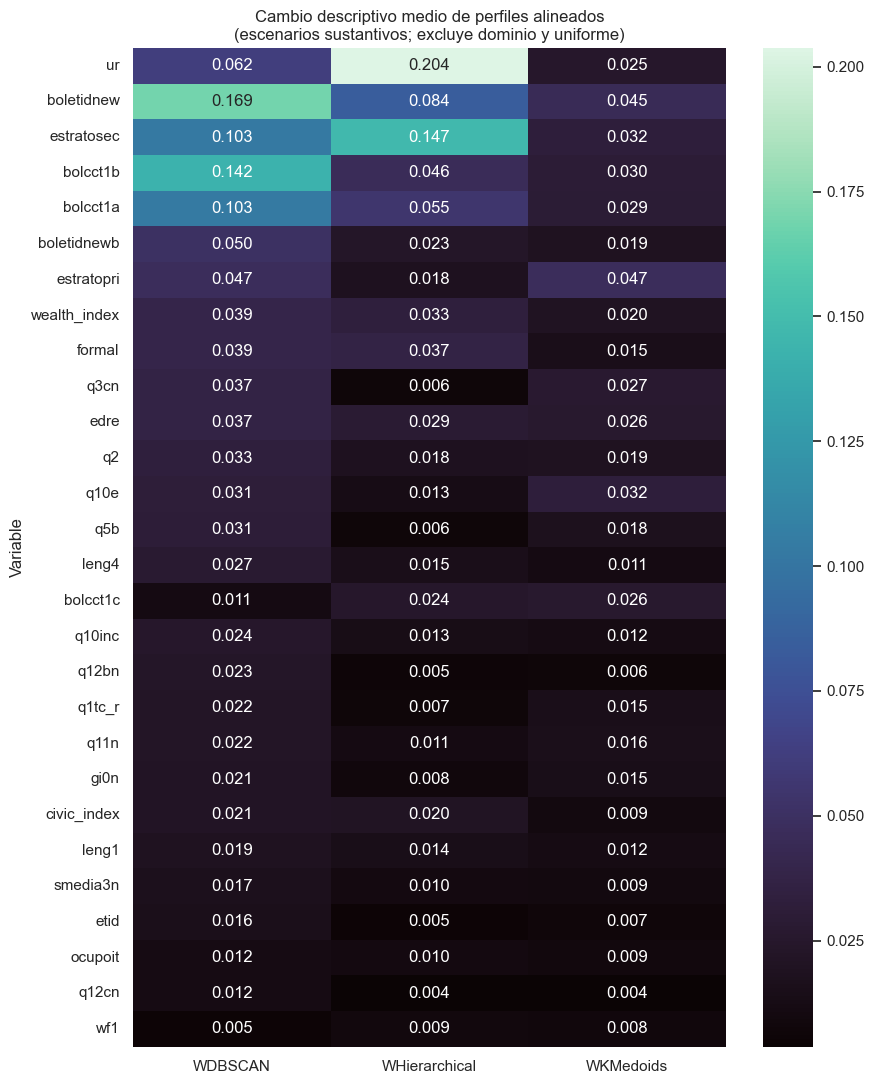

In [14]:
heat = aggregate_sensitivity.pivot(index="variable", columns="algoritmo", values="sensibilidad_media").fillna(0)
heat = heat.loc[heat.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 11))
sns.heatmap(heat, cmap="mako", annot=True, fmt=".3f", ax=ax)
ax.set(title="Cambio descriptivo medio de perfiles alineados\n(escenarios sustantivos; excluye dominio y uniforme)", xlabel="", ylabel="Variable")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "sensibilidad_perfiles_alineados.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

### RESUMEN DE RESULTADOS
La síntesis se genera a partir de las comparaciones con parámetros fijos. Identifica los escenarios con mayor y menor similitud frente al dominio y recuerda el alcance de las métricas utilizadas.

In [15]:
non_domain = assignments_df.query("escenario != 'dominio'")
lowest = non_domain.loc[non_domain.groupby("algoritmo")["ari_vs_dominio"].idxmin(), ["algoritmo", "escenario", "ari_vs_dominio"]]
highest = non_domain.loc[non_domain.groupby("algoritmo")["ari_vs_dominio"].idxmax(), ["algoritmo", "escenario", "ari_vs_dominio"]]
db_cov = coverage_df.set_index("escenario")

stable_lines = [
    f"- {r.algoritmo}: el escenario no-dominio más próximo por ARI fue `{r.escenario}` (ARI={r.ari_vs_dominio:.3f})."
    for r in highest.itertuples()
]
sensitive_lines = [
    f"- {r.algoritmo}: el mayor cambio de asignaciones apareció en `{r.escenario}` (ARI={r.ari_vs_dominio:.3f})."
    for r in lowest.itertuples()
]
sensitive_lines.append(
    f"- W-DBSCAN: la cobertura varió entre {db_cov.cobertura_pct.min():.1f}% y {db_cov.cobertura_pct.max():.1f}%; "
    f"por ello sus métricas internas no se comparan como si evaluaran la misma población."
)
not_conclude = [
    "- No se identifica una partición verdadera ni se demuestra superioridad causal de un escenario.",
    "- Un ARI alto describe estabilidad frente al dominio; no valida los pesos teóricos.",
    "- Las métricas internas no demuestran relevancia social y no deben ordenarse directamente entre espacios o coberturas distintas.",
    "- Las diferencias de perfiles son descriptivas, no importancias causales.",
]
synthesis = "# Qué permanece estable\n\n" + "\n".join(stable_lines)
synthesis += "\n\n# Qué resulta sensible a los pesos\n\n" + "\n".join(sensitive_lines)
synthesis += "\n\n# Qué no puede concluirse\n\n" + "\n".join(not_conclude) + "\n"
(OUTPUT_DIR / "sintesis_metodologica.md").write_text(synthesis, encoding="utf-8")
display(Markdown(synthesis))


# Qué permanece estable

- WDBSCAN: el escenario no-dominio más próximo por ARI fue `atenuacion_participacion_informacion` (ARI=0.892).
- WHierarchical: el escenario no-dominio más próximo por ARI fue `atenuacion_identidad` (ARI=0.877).
- WKMedoids: el escenario no-dominio más próximo por ARI fue `atenuacion_participacion_informacion` (ARI=0.874).

# Qué resulta sensible a los pesos

- WDBSCAN: el mayor cambio de asignaciones apareció en `intensificado_025_1` (ARI=-0.039).
- WHierarchical: el mayor cambio de asignaciones apareció en `atenuacion_territorial` (ARI=-0.020).
- WKMedoids: el mayor cambio de asignaciones apareció en `atenuacion_identidad` (ARI=0.599).
- W-DBSCAN: la cobertura varió entre 0.0% y 67.5%; por ello sus métricas internas no se comparan como si evaluaran la misma población.

# Qué no puede concluirse

- No se identifica una partición verdadera ni se demuestra superioridad causal de un escenario.
- Un ARI alto describe estabilidad frente al dominio; no valida los pesos teóricos.
- Las métricas internas no demuestran relevancia social y no deben ordenarse directamente entre espacios o coberturas distintas.
- Las diferencias de perfiles son descriptivas, no importancias causales.


### REGISTRO Y VERIFICACIÓN DE ARCHIVOS
El manifiesto registra el entorno, las entradas, los parámetros y los archivos generados. Se comprueba la existencia y el hash de cada archivo; el propio manifiesto se excluye del cálculo de hash para evitar la autorreferencia.

In [16]:
assert sha256_file(DATASET) == dataset_hash, 'El dataset cambió durante la ejecución.'
assert sha256_file(WEIGHTS_PATH) == weights_hash, 'Los pesos cambiaron durante la ejecución.'
assert len(labels_store) == 24 and len(metrics_df) == 48 and len(summary) == 24
warnings_list = [
    "El repositorio estaba modificado durante la ejecución; consulte git_status_at_execution.",
    "El control uniforme es técnico y no sustituye la referencia de dominio.",
    "W-DBSCAN reajusta PCA17 por escenario; la población evaluada cambia con la cobertura.",
    "Las variables nominales permanecen codificadas numéricamente según el pipeline canónico.",
]
expected_artifacts = [
    "definicion_pesos_escenarios.csv", "resumen_escenarios.csv", "comparacion_asignaciones.csv",
    "comparacion_metricas.csv", "comparacion_tamanos_ruido.csv", "etiquetas.csv",
    "distribucion_tamanos.csv", "cobertura_ruido.csv", "correspondencia_etiquetas.csv",
    "comparacion_perfiles.csv", "variables_mas_sensibles_por_escenario.csv",
    "variables_mas_sensibles.csv", "sintesis_metodologica.md",
    "figuras/ari_vs_dominio.png", "figuras/distribucion_tamanos_alineados.png",
    "figuras/wdbscan_cobertura_ruido.png", "figuras/metricas_geometrias.png",
    "figuras/sensibilidad_perfiles_alineados.png", "manifiesto.json",
]
artifact_entries = []
for relative in expected_artifacts:
    path = OUTPUT_DIR / relative
    if relative == "manifiesto.json":
        artifact_entries.append({"ruta": relative, "sha256": None, "bytes": None, "nota": "autorreferencia"})
    else:
        assert path.exists() and path.stat().st_size > 0, f"Artefacto ausente o vacío: {relative}"
        artifact_entries.append({"ruta": relative, "sha256": sha256_file(path), "bytes": path.stat().st_size})

manifest = {
    "schema": "electocluster-sensibilidad-ponderacion-v1",
    "fecha_hora": datetime.now(ZoneInfo("America/La_Paz")).isoformat(),
    "notebook": str(NOTEBOOK_PATH),
    "dataset": {"ruta": str(DATASET), "sha256": dataset_hash, "shape": list(X.shape), "columnas": EXPECTED_FEATURES},
    "pesos_dominio": {"ruta": str(WEIGHTS_PATH), "sha256": weights_hash, "copia_28_variables": domain.to_dict()},
    "git": {"commit": commit, "rama": branch, "status_limpio": len(git_status_at_execution.splitlines()) <= 1,
            "git_status_at_execution": git_status_at_execution},
    "entorno": environment,
    "parametros_fijos": PARAMS,
    "escenarios": {name: {"pesos": weights.to_dict(), "variables_bloque": BLOCKS.get(name, [])} for name, weights in scenarios.items()},
    "verificaciones": {
        "dataset_hash": "PASS", "shape_1706x28": "PASS", "sin_faltantes_infinitos": "PASS",
        "orden_variables": "PASS", "escenarios_no_duplicados": "PASS", "bloques_solo_variables_previstas": "PASS",
        "parametros_constantes": "PASS", "uniforme_equivale_euclidiana": "PASS",
        "linea_base_canonica": baseline_checks_df.to_dict(orient="records"),
    },
    # El inventario completo describe la ejecución local; la publicación es selectiva.
    "archivos_generados": artifact_entries,
    "paquete_publicacion": {
        "archivos_incluidos": [
            relative for relative in expected_artifacts
            if relative not in {"etiquetas.csv", "sintesis_metodologica.md"}
        ],
        "archivos_solo_locales": ["etiquetas.csv", "sintesis_metodologica.md"],
        "nota": (
            "archivos_generados registra todas las salidas de la ejecución local. "
            "Los hashes de archivos_solo_locales documentan su procedencia, "
            "pero esos archivos no se distribuyen en el repositorio. "
            "El dataset de entrada tampoco se incluye."
        ),
    },
    "advertencias": warnings_list,
    "ejecuciones_incompletas": [],
}
(OUTPUT_DIR / "manifiesto.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")

actual_files = sorted(p.relative_to(OUTPUT_DIR).as_posix() for p in OUTPUT_DIR.rglob("*") if p.is_file())
assert actual_files == sorted(expected_artifacts), ("Inventario no coincide", actual_files, expected_artifacts)
for entry in manifest["archivos_generados"]:
    path = OUTPUT_DIR / entry["ruta"]
    assert path.exists() and path.stat().st_size > 0
    if entry["sha256"] is not None:
        assert sha256_file(path) == entry["sha256"]

print(f"Artefactos validados: {len(actual_files)}")
print(f"Manifiesto: {OUTPUT_DIR / 'manifiesto.json'}")


Artefactos validados: 19
Manifiesto: D:\GradoProyec\electocluster\results\pruebas_sensibilidad_ponderacion\manifiesto.json


### ALCANCE DE LA COMPARACIÓN
Los resultados describen la sensibilidad a los pesos con los parámetros de agrupamiento fijados. La estabilidad frente al dominio no valida por sí sola su fundamentación teórica, y las métricas internas no demuestran relevancia social. Una comparación con reoptimización de `k`, `eps` o `min_samples` requiere un análisis separado.